# 3.3 K-Nearest Neighbors

Basic mechanism, sensitivity to feature scale, the cost/accuracy trade-off,
and choosing K -- on the same churn target/features/split.

## Setup

Throughout this notebook (and every other notebook in this folder) we reuse
the **same 300-row synthetic customer table** (`data/customers.csv`, see
`data/generate_customers.py`): a small telecom/subscription dataset with a
continuous target (`monthly_spend`) for regression notebooks and a binary
target (`churned`) for classification notebooks, plus a block of numeric
features used for resampling, evaluation-metric, dimensionality-reduction
and clustering demos. The point isn't the dataset -- it's small and
synthetic on purpose -- the point is seeing each technique applied to
something you already recognise from the last notebook.

Every classification notebook predicts the **same target, from the same
features, on the same train/test split** -- so the confusion matrix/ROC/AUC
numbers below are directly comparable to the other technique notebooks in
this folder.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath("common"))
sys.path.insert(0, os.path.abspath("../common"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

CUSTOMERS_PATH = "data/customers.csv" if os.path.exists("data/customers.csv") else "../data/customers.csv"
df = pd.read_csv(CUSTOMERS_PATH)
df.head()

,customer_id,age,region,tenure_months,income_k,monthly_usage,support_calls,discount_pct,satisfaction,monthly_spend,churned
0,C0001,45.7,South,90.7,78.1,8.3,2,0,8.12,39.35,0
1,C0002,29.5,North,54.9,58.4,27.3,6,5,5.80,51.69,0
2,C0003,51.0,West,28.6,73.3,13.9,5,0,5.48,37.75,1
3,C0004,53.3,West,22.9,106.5,13.3,6,10,9.25,34.31,1
4,C0005,18.6,West,45.7,35.5,67.2,6,15,7.26,52.28,0


In [2]:
from sklearn.model_selection import train_test_split
from plotting import plot_confusion, plot_roc, plot_lift

features = ["age","tenure_months","income_k","monthly_usage","support_calls","discount_pct","satisfaction"]
X = df[features]
y = df["churned"]
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, random_state=0, stratify=y)
print("train:", Xtr.shape, " test:", Xte.shape, " churn rate (train/test):", round(ytr.mean(),3), round(yte.mean(),3))

train: (210, 7)  test: (90, 7)  churn rate (train/test): 0.338 0.344


## Sensitivity to scale: why we must standardise first

In [3]:
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import roc_auc_score

scaler = StandardScaler().fit(Xtr)
Xtr_s = scaler.transform(Xtr)
Xte_s = scaler.transform(Xte)

knn_raw = KNeighborsClassifier(n_neighbors=15).fit(Xtr, ytr)
knn_scaled = KNeighborsClassifier(n_neighbors=15).fit(Xtr_s, ytr)
print("AUC without scaling:", round(roc_auc_score(yte, knn_raw.predict_proba(Xte)[:, 1]), 3))
print("AUC with scaling   :", round(roc_auc_score(yte, knn_scaled.predict_proba(Xte_s)[:, 1]), 3))

AUC without scaling: 0.607
AUC with scaling   : 0.724


`income_k` and `age` live on a much bigger numeric scale than
`discount_pct` or `support_calls` -- without standardising, distance is
dominated by whichever feature happens to have the largest raw range, not
by which features actually matter. This is the "sensitivity to scale"
slide made concrete.

## Choosing K: the cost/accuracy trade-off

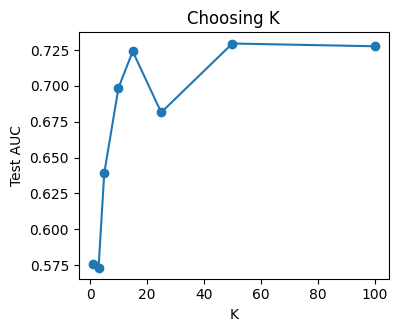

Best K on this split: 50


In [4]:
ks = [1, 3, 5, 10, 15, 25, 50, 100]
aucs = []
for k in ks:
    m = KNeighborsClassifier(n_neighbors=k).fit(Xtr_s, ytr)
    aucs.append(roc_auc_score(yte, m.predict_proba(Xte_s)[:, 1]))

fig, ax = plt.subplots(figsize=(4, 3.2))
ax.plot(ks, aucs, marker="o")
ax.set_xlabel("K"); ax.set_ylabel("Test AUC"); ax.set_title("Choosing K")
plt.show()
best_k = ks[int(np.argmax(aucs))]
print("Best K on this split:", best_k)

In [5]:
clf = KNeighborsClassifier(n_neighbors=best_k).fit(Xtr_s, ytr)

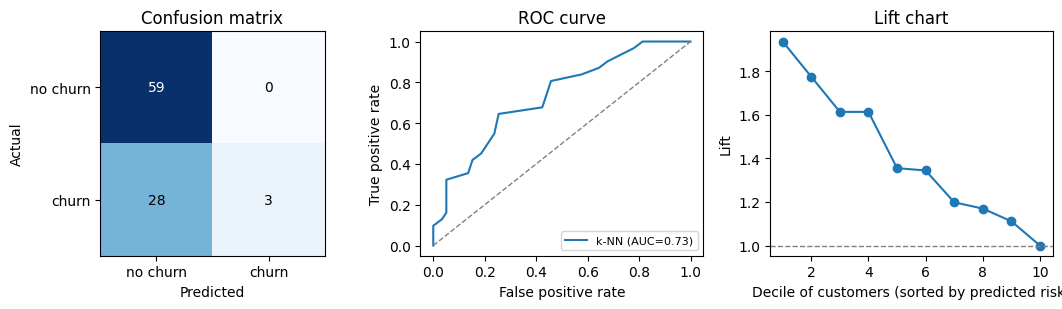

AUC: 0.73


In [6]:
y_pred = clf.predict(Xte_s)
y_score = clf.predict_proba(Xte_s)[:, 1]

fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))
plot_confusion(yte, y_pred, ax=axes[0])
auc_val = plot_roc(yte, y_score, ax=axes[1], label="k-NN")
plot_lift(yte, y_score, ax=axes[2])
plt.tight_layout(); plt.show()
print("AUC:", round(auc_val, 3))

**Wrap-up**: k-NN has no training phase to speak of, but every prediction
scans the whole (scaled!) training set -- cheap for a dataset this small,
noticeably more expensive as n grows, which is the "computational cost vs.
predictive power" trade-off from the slides.